# 15 · Graph attention (GAT) on the patient-similarity networks

Notebook 14 gave every linked stay the same weight (GraphSAGE averages its neighbours). **GAT** (`torch_geometric.nn.models.GAT`) *learns* a weight for each link: for stay *i* and neighbour *j* it scores how useful *j* is for *i*, turns the scores over *i*'s neighbours into weights that add to 1, and averages with those. Several attention **heads** each learn their own weights. So GAT can in principle listen more to some neighbours than others, or put nearly all its weight on the stay itself and ignore the network. This notebook asks whether that makes the network useful, and **shows where the attention actually goes**.

**Same protocol as notebooks 13 and 14**, so every number can sit next to a linear or GraphSAGE one: the same patient-grouped 60/20/20 splits (same split seeds), columns standardised with the training stays only, settings and stopping epoch chosen on the validation stays, test stays scored once, repeated over `SEEDS` and reported as mean and spread.

**Three models, as in notebook 14:**

| model | what it is |
|---|---|
| `gat` | GAT on the saved network |
| `mlp` | the *same* architecture and training with **every link removed** (each stay then attends only to itself). `gat − mlp` on identical splits is what the network adds |
| `gat_nosame` | GAT with the links between two stays of the **same patient** removed (about a third of links) |

**Things to know before reading the numbers**

- Full-batch and **transductive**, exactly as in notebook 14: the whole network is visible, only the *training* stays' outcomes are used, and a patient's stays always sit in one split.
- `hidden` is **split across heads** (64 hidden with 4 heads = 16 per head). Every stay also attends to itself.
- Like GraphSAGE, GAT **ignores the stored edge weights**. No link features are given either, so the links enter as present / absent.
- A link's attention score is computed from the **features of its two stays only**. Attention can favour a kind of link only if that kind is recognisable from the features.
- With dropout *p*, *p* is applied to the hidden features **and to the attention weights**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from ehrgraph.eval.aggregate import write_aggregate  # noqa: F401
from ehrgraph.gnn import gat as G
from ehrgraph.gnn.linear_regressor import YEAR_BANDS
from ehrgraph.gnn.node_features import FEATURE_SETS, LEAKABLE_BLOCKS
from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()
nf.apply_style()

TASKS = {"guo_los": "long stay", "new_hypertension": "new high blood pressure"}
NAME = {"safe": "honest", "leaky": "cheating", "null": "random"}
SEEDS = range(5)               # keep equal to notebook 14 so GAT and GraphSAGE are paired on the same splits
CONFIGS = G.CONFIGS            # small grid, chosen on the validation stays for every split seed
print("device:", G.pick_device(), "| configs:", len(CONFIGS), "| seeds:", len(SEEDS))

/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


data folder: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/data/omop
results go to: /home/ianstedham/network-analysis-ml/trimmed-dataset/ehrshot-patient-graphs/results/aggregate
device: cpu | configs: 2 | seeds: 5


## Load the inputs from notebook 12

The same file and alignment checks as notebooks 13 and 14.

In [2]:
datasets, years = {}, {}
for task in TASKS:
    datasets[task] = torch.load(p.results / f"gnn_inputs_{task}.pt", weights_only=False)

    lab = p.labels(task)
    lab = lab[lab["patient_id"].isin(set(p.diagnoses))].reset_index(drop=True)
    d0 = next(iter(datasets[task].values()))
    assert (lab["value"].astype(int).to_numpy() == d0.y.numpy()).all(), "labels are not aligned with the saved stays"
    assert (pd.factorize(lab["patient_id"])[0] == d0.patient_idx.numpy()).all(), "patients are not aligned"
    years[task] = pd.to_datetime(lab["prediction_time"]).dt.year.to_numpy()
    print(f"{TASKS[task]}: {d0.num_nodes:,} stays, {d0.y.float().mean():.1%} positive, "
          f"{d0.edge_index.shape[1] // 2:,} links, {d0.edge_attr.float().mean():.1%} same-patient, "
          f"{len(datasets[task])} saved combinations")

long stay: 6,998 stays, 25.4% positive, 18,581 links, 37.8% same-patient, 16 saved combinations
new high blood pressure: 3,511 stays, 12.8% positive, 9,787 links, 29.4% same-patient, 16 saved combinations


## Which feature sets and runs

The same choices as notebook 14: the **diagnosis features** (`dx`) and the **CLMBR** vector when notebook 12 built it; the network-derived feature sets (`n2v`, `structure`) are left out because they would feed the same network in twice.

- `gat` runs on every saved network (honest, cheating, random) × every feature source (honest or cheating diagnoses).
- `mlp` has no links, so it needs one run per feature source.
- `gat_nosame` runs on the honest and cheating networks with honest diagnoses.

If CLMBR is present, every run for that question is restricted to the stays that **have** a CLMBR vector, so all models are scored on the same stays.

In [3]:
GNN_FEATURES = [fs for fs in ("dx", "clmbr") if any(k[2] == fs for ds in datasets.values() for k in ds)]

SUBSET = {t: None for t in TASKS}
for t in TASKS:
    d = next((d for k, d in datasets[t].items() if k[2] == "clmbr"), None)
    if d is not None:
        names = list(d.feature_names)
        vec = [i for i, n in enumerate(names) if n != "has_clmbr"]
        has = np.abs(d.x[:, vec].numpy()).sum(1) > 0               # a stay with no CLMBR vector is all zeros
        if not has.all():
            SUBSET[t] = has
        print(f"{TASKS[t]}: CLMBR vector for {has.mean():.1%} of stays" + (" -> restricting every run to them" if SUBSET[t] is not None else ""))

NEEDS_DX = lambda fs: any(b in LEAKABLE_BLOCKS for b in FEATURE_SETS[fs])

def pretty(model, key):
    g, s, fs = key
    parts = [model, fs]
    if model != "mlp":
        parts.append(f"net: {NAME[g]}")
    if NEEDS_DX(fs):
        parts.append(f"feat: {NAME[s]}")
    return " | ".join(parts)

runs = {}
for t, ds in datasets.items():
    r = []
    for fs in GNN_FEATURES:
        ks = [k for k in ds if k[2] == fs and (NEEDS_DX(fs) or k[1] == "safe")]       # the diagnosis source is irrelevant to CLMBR: run it once
        r += [("gat", k) for k in ks]
        r += [("mlp", k) for k in ks if k[0] == "safe"]
        r += [("gat_nosame", k) for k in ks if k[0] in ("safe", "leaky") and k[1] == "safe"]
    runs[t] = r
    print(TASKS[t], len(r), "runs x", len(SEEDS), "seeds")

long stay 9 runs x 5 seeds
new high blood pressure 9 runs x 5 seeds


## Run

A quick timing check first: one run, one seed. GAT is slower than GraphSAGE (several heads, plus attention scores for every link), so check this before running everything; lower `SEEDS` or `CONFIGS` if it is too long.

In [4]:
import time
t1 = next(iter(TASKS))
t0 = time.time()
m0, k0 = runs[t1][0]
_ = G.evaluate_data(datasets[t1][k0], m0, 0, CONFIGS, years[t1], SUBSET[t1])
one = time.time() - t0
total = sum(len(r) for r in runs.values()) * len(SEEDS) * one
print(f"one run: {one:.1f}s -> about {total / 60:.0f} min for everything (rough: later runs differ in size)")

one run: 7.8s -> about 12 min for everything (rough: later runs differ in size)


In [5]:
res = {t: G.run_models(datasets[t], runs[t], SEEDS, year=years[t], subset=SUBSET[t], configs=CONFIGS, log=lambda s: None) for t in TASKS}

tables = {}
for t in TASKS:
    s = G.summarize(res[t])
    s.index = [pretty(m, (g, so, f)) for m, g, so, f in s.index]
    tables[t] = s
    print(f"{TASKS[t]} - test AUROC, mean and spread over {len(SEEDS)} splits")
    display(s[["mean", "sd", "test_ap", "epoch", "n_features"]].round(3))

long stay - test AUROC, mean and spread over 5 splits


,mean,sd,test_ap,epoch,n_features
gat | dx | net: cheating | feat: cheating,0.754,0.018,0.495,47.6,65
gat | dx | net: cheating | feat: honest,0.758,0.013,0.499,58.8,65
gat | dx | net: random | feat: honest,0.671,0.004,0.425,70.6,65
gat | dx | net: honest | feat: cheating,0.761,0.020,0.515,21.8,65
gat | dx | net: honest | feat: honest,0.765,0.010,0.519,42.6,65
gat_nosame | dx | net: cheating | feat: honest,0.770,0.016,0.521,59.4,65
gat_nosame | dx | net: honest | feat: honest,0.772,0.009,0.530,59.4,65
mlp | dx | feat: cheating,0.768,0.019,0.509,25.6,65
mlp | dx | feat: honest,0.777,0.015,0.545,28.8,65


new high blood pressure - test AUROC, mean and spread over 5 splits


,mean,sd,test_ap,epoch,n_features
gat | dx | net: cheating | feat: cheating,0.837,0.030,0.431,51.2,65
gat | dx | net: cheating | feat: honest,0.722,0.035,0.315,39.4,65
gat | dx | net: random | feat: honest,0.578,0.028,0.171,65.6,65
gat | dx | net: honest | feat: cheating,0.795,0.033,0.354,80.4,65
gat | dx | net: honest | feat: honest,0.672,0.030,0.278,27.4,65
gat_nosame | dx | net: cheating | feat: honest,0.726,0.038,0.322,35.6,65
gat_nosame | dx | net: honest | feat: honest,0.670,0.030,0.265,26.8,65
mlp | dx | feat: cheating,0.894,0.025,0.555,54.6,65
mlp | dx | feat: honest,0.691,0.037,0.273,54.2,65


`epoch` is the average stopping epoch (the epoch with the best validation AUROC). Values near the maximum of 200 mean training was still improving; values under about 10 mean the model peaked almost immediately and is probably just reading the features.

### Which settings were chosen

In [6]:
for t in TASKS:
    print(TASKS[t])
    display(res[t].groupby("model")[["hidden", "heads", "dropout", "weight_decay"]].agg(lambda s: s.value_counts().to_dict()))

long stay


,hidden,heads,dropout,weight_decay
model,,,,
gat,{64: 25},{4: 25},"{0.5: 19, 0.2: 6}","{0.001: 19, 0.01: 6}"
gat_nosame,{64: 10},{4: 10},{0.5: 10},{0.001: 10}
mlp,{64: 10},{4: 10},"{0.5: 7, 0.2: 3}","{0.001: 7, 0.01: 3}"


new high blood pressure


,hidden,heads,dropout,weight_decay
model,,,,
gat,{64: 25},{4: 25},"{0.5: 14, 0.2: 11}","{0.001: 14, 0.01: 11}"
gat_nosame,{64: 10},{4: 10},"{0.5: 6, 0.2: 4}","{0.001: 6, 0.01: 4}"
mlp,{64: 10},{4: 10},"{0.5: 6, 0.2: 4}","{0.001: 6, 0.01: 4}"


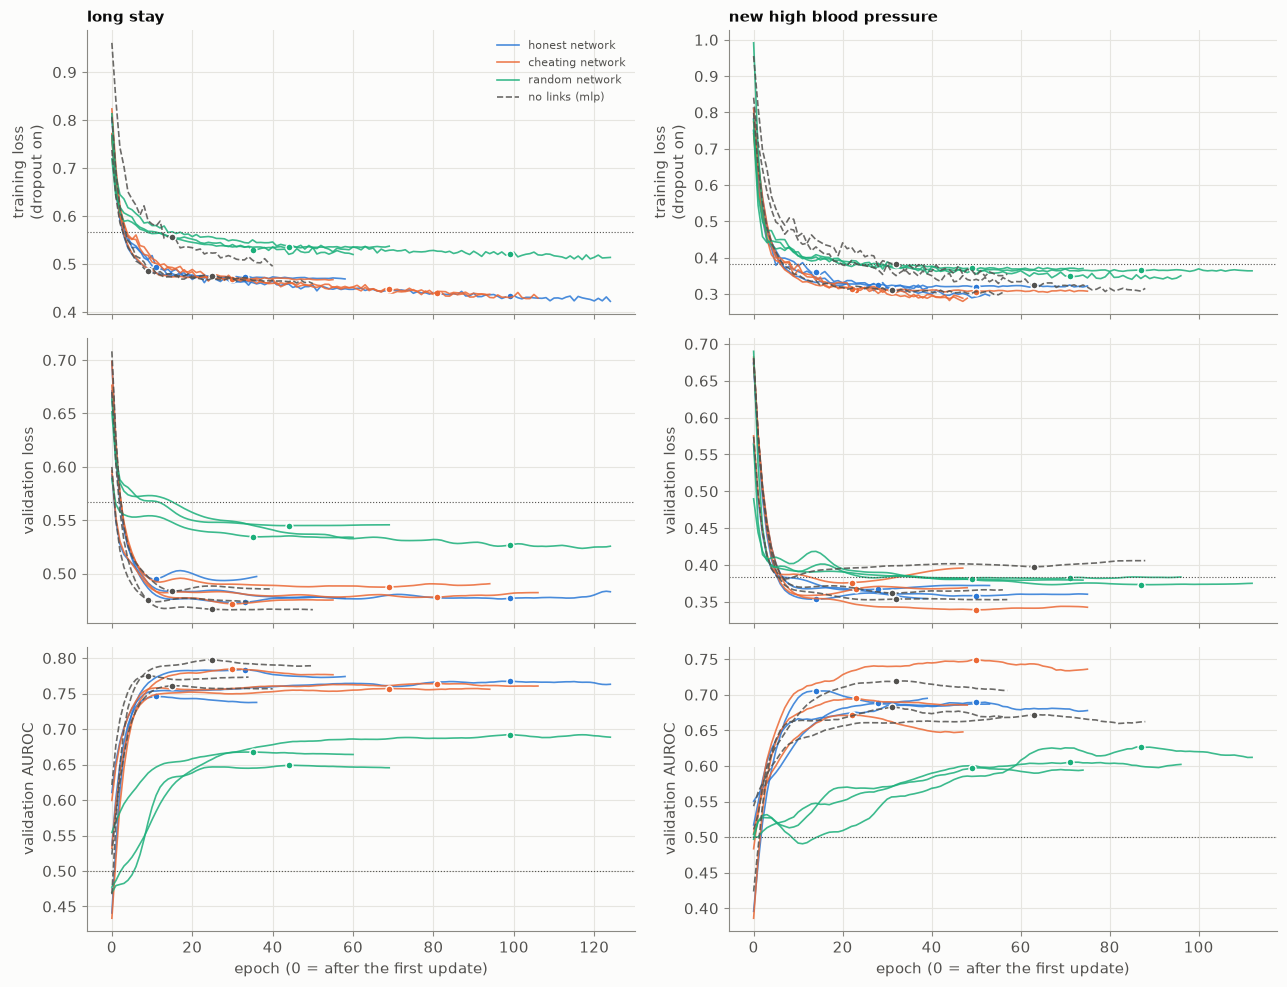

kept epoch  last epoch  \
question                run                                        
long stay               cheating network      60.000      85.000   
                        honest network        47.667      72.667   
                        no links (mlp)        16.333      41.333   
                        random network        59.333      84.333   
new high blood pressure cheating network      31.667      56.667   
                        honest network        30.667      55.667   
                        no links (mlp)        42.000      67.000   
                        random network        69.000      94.000   

                                          train loss at kept  \
question                run                                    
long stay               cheating network               0.452   
                        honest network                 0.467   
                        no links (mlp)                 0.505   
                        random network                 0.528   
new high blood pressure cheating network               0.311   
                        honest network                 0.335   
                        no links (mlp)                 0.340   
                        random network                 0.362   

                                          val loss at kept  \
question                run                                  
long stay               cheating network             0.479   
                        honest network               0.481   
                        no links (mlp)               0.475   
                        random network               0.535   
new high blood pressure cheating network             0.361   
                        honest network               0.360   
                        no links (mlp)               0.371   
                        random network               0.379   

                                          epoch of lowest val loss  \
question                run                                          
long stay               cheating network                    57.333   
                        honest network                      52.000   
                        no links (mlp)                      18.333   
                        random network                      71.667   
new high blood pressure cheating network                    27.667   
                        honest network                      26.667   
                        no links (mlp)                      31.000   
                        random network                      71.333   

                                          lowest val loss  val AUROC at kept  
question                run                                                   
long stay               cheating network            0.479              0.769  
                        honest network              0.481              0.766  
                        no links (mlp)              0.474              0.778  
                        random network              0.534              0.670  
new high blood pressure cheating network            0.358              0.705  
                        honest network              0.359              0.694  
                        no links (mlp)              0.365              0.691  
                        random network              0.378              0.610

In [7]:
NET = "gat"
FIG = "15_training_curves.png"   
CSV = "gat_training_curves.csv"  

CURVE_SEEDS = range(3)
CURVE_RUNS = {                            # label -> (model, saved network); diagnoses are the honest ones
    "honest network":   (NET,  ("safe", "safe", "dx")),
    "cheating network": (NET,  ("leaky", "safe", "dx")),
    "random network":   (NET,  ("null", "safe", "dx")),
    "no links (mlp)":   ("mlp", ("safe", "safe", "dx")),
}
CURVE_STYLE = {"honest network": ("#2a78d6", "-"), "cheating network": ("#eb6834", "-"),
               "random network": ("#1baf7a", "-"), "no links (mlp)": ("#52514e", "--")}

# G.training_curves reruns the same seeds and settings as the results above and returns one row per
# (setting, epoch). It never touches the test stays.
curves = []
for t in TASKS:
    for label, (model, key) in CURVE_RUNS.items():
        if key not in datasets[t]:
            continue
        for s in CURVE_SEEDS:
            c = G.training_curves(datasets[t][key], model, s, CONFIGS, subset=SUBSET[t])
            c.insert(0, "question", TASKS[t]); c.insert(1, "run", label)
            curves.append(c)
curves = pd.concat(curves, ignore_index=True)
kept = curves[curves["chosen"]]            # the setting that won on validation, per run and seed

# the loss of always predicting the base rate
def base_loss(pr):
    return -(pr * np.log(pr) + (1 - pr) * np.log(1 - pr))
BASE = {t: base_loss(next(iter(datasets[t].values())).y.float().mean().item()) for t in TASKS}

ROWS = [("train_loss", "training loss\n(dropout on)"), ("val_loss", "validation loss"), ("val_auc", "validation AUROC")]
fig, axes = plt.subplots(len(ROWS), len(TASKS), figsize=(13, 10), sharex="col")
axes = np.asarray(axes).reshape(len(ROWS), len(TASKS))
for j, t in enumerate(TASKS):
    for i, (col, ylab) in enumerate(ROWS):
        ax = axes[i, j]
        for label, (colr, ls) in CURVE_STYLE.items():
            sub = kept[(kept["question"] == TASKS[t]) & (kept["run"] == label)]
            for k, (s, g) in enumerate(sub.groupby("seed")):
                g = g.reset_index(drop=True)
                ax.plot(g["epoch"], g[col], color=colr, ls=ls, lw=1.2, alpha=0.85, label=label if k == 0 else None)
                be = int(g["best_epoch"].iloc[0])
                ax.plot(be, g[col].iloc[be], "o", ms=5, color=colr, mec="white", mew=1)     # the epoch that was kept
        if col != "val_auc":
            ax.axhline(BASE[t], color="#52514e", lw=0.8, ls=":")                            # predicting the base rate
        else:
            ax.axhline(0.5, color="#52514e", lw=0.8, ls=":")
        ax.set_ylabel(ylab)
        if i == 0:
            ax.set_title(TASKS[t])
        if i == len(ROWS) - 1:
            ax.set_xlabel("epoch (0 = after the first update)")
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
nf.save(fig, p.figures / FIG)
plt.show()

# one row per run, averaged over the seeds
def curve_summary(df):
    rows = []
    for (q, run, s), g in df.groupby(["question", "run", "seed"]):
        g = g.reset_index(drop=True)
        be = int(g["best_epoch"].iloc[0])
        rows.append({"question": q, "run": run, "kept epoch": be, "last epoch": int(g["epoch"].iloc[-1]),
                     "train loss at kept": g["train_loss"].iloc[be], "val loss at kept": g["val_loss"].iloc[be],
                     "epoch of lowest val loss": int(g["val_loss"].idxmin()), "lowest val loss": g["val_loss"].min(),
                     "val AUROC at kept": g["val_auc"].iloc[be]})
    return pd.DataFrame(rows).groupby(["question", "run"], sort=False).mean(numeric_only=True)

display(curve_summary(kept).round(3))
curves.to_csv(p.results / CSV, index=False)    # aggregate numbers only: seed, setting, epoch, losses


## The questions we care about

Each row is a **paired difference** in test AUROC (A minus B) on identical splits, so split luck cancels. `fraction_a_higher` is the share of splits where A won. A difference smaller than its `sd` is not a finding.

Read the first block for **what the network adds**, the second for **whether cheating changes anything**.

In [8]:
H = ("safe", "safe", "dx")           # honest network, honest diagnoses
PAIRS = [
    # --- what does the network add? (same features, links on vs off)
    ("network adds, honest net:  gat - mlp",                     ("gat", *H),                        ("mlp", *H)),
    ("network adds, cheating net:  gat - mlp",                   ("gat", "leaky", "safe", "dx"),     ("mlp", *H)),
    ("network adds, random net:  gat - mlp",                     ("gat", "null", "safe", "dx"),      ("mlp", *H)),
    ("real vs random network (gat)",                             ("gat", *H),                        ("gat", "null", "safe", "dx")),
    ("without same-patient links:  gat_nosame - mlp",            ("gat_nosame", *H),                 ("mlp", *H)),
    ("same-patient links matter?  gat - gat_nosame",             ("gat", *H),                        ("gat_nosame", *H)),
    # --- does cheating change anything?
    ("cheating network vs honest (gat, honest dx)",              ("gat", "leaky", "safe", "dx"),     ("gat", *H)),
    ("cheating diagnoses vs honest (gat, honest net)",           ("gat", "safe", "leaky", "dx"),     ("gat", *H)),
    ("both cheat vs both honest (gat)",                          ("gat", "leaky", "leaky", "dx"),    ("gat", *H)),
    ("cheating diagnoses vs honest (mlp, no network)",           ("mlp", "safe", "leaky", "dx"),     ("mlp", *H)),
    # --- CLMBR (only if notebook 12 built it)
    ("CLMBR vs diagnoses (gat, honest net)",                     ("gat", "safe", "safe", "clmbr"),   ("gat", *H)),
    ("network adds to CLMBR:  gat - mlp",                        ("gat", "safe", "safe", "clmbr"),   ("mlp", "safe", "safe", "clmbr")),
]
out = []
for t in TASKS:
    have = {tuple(r) for r in res[t][G.KEY].drop_duplicates().to_numpy()}
    for name, a, b in PAIRS:
        if a in have and b in have:
            out.append({"question": TASKS[t], "A minus B": name, **G.paired(res[t], a, b)})
if out:
    display(pd.DataFrame(out).set_index(["question", "A minus B"]).round(3))
else:
    print("none of these comparisons were run")

mean_diff  \
question                A minus B                                                   
long stay               network adds, honest net:  gat - mlp               -0.013   
                        network adds, cheating net:  gat - mlp             -0.019   
                        network adds, random net:  gat - mlp               -0.106   
                        real vs random network (gat)                        0.093   
                        without same-patient links:  gat_nosame - mlp      -0.005   
                        same-patient links matter?  gat - gat_nosame       -0.008   
                        cheating network vs honest (gat, honest dx)        -0.006   
                        cheating diagnoses vs honest (gat, honest net)     -0.004   
                        both cheat vs both honest (gat)                    -0.010   
                        cheating diagnoses vs honest (mlp, no network)     -0.010   
new high blood pressure network adds, honest net:  gat - mlp               -0.018   
                        network adds, cheating net:  gat - mlp              0.032   
                        network adds, random net:  gat - mlp               -0.113   
                        real vs random network (gat)                        0.094   
                        without same-patient links:  gat_nosame - mlp      -0.021   
                        same-patient links matter?  gat - gat_nosame        0.002   
                        cheating network vs honest (gat, honest dx)         0.050   
                        cheating diagnoses vs honest (gat, honest net)      0.122   
                        both cheat vs both honest (gat)                     0.164   
                        cheating diagnoses vs honest (mlp, no network)      0.203   

                                                                           sd  \
question                A minus B                                               
long stay               network adds, honest net:  gat - mlp            0.012   
                        network adds, cheating net:  gat - mlp          0.011   
                        network adds, random net:  gat - mlp            0.015   
                        real vs random network (gat)                    0.012   
                        without same-patient links:  gat_nosame - mlp   0.014   
                        same-patient links matter?  gat - gat_nosame    0.006   
                        cheating network vs honest (gat, honest dx)     0.010   
                        cheating diagnoses vs honest (gat, honest net)  0.025   
                        both cheat vs both honest (gat)                 0.019   
                        cheating diagnoses vs honest (mlp, no network)  0.029   
new high blood pressure network adds, honest net:  gat - mlp            0.016   
                        network adds, cheating net:  gat - mlp          0.015   
                        network adds, random net:  gat - mlp            0.048   
                        real vs random network (gat)                    0.050   
                        without same-patient links:  gat_nosame - mlp   0.016   
                        same-patient links matter?  gat - gat_nosame    0.006   
                        cheating network vs honest (gat, honest dx)     0.018   
                        cheating diagnoses vs honest (gat, honest net)  0.033   
                        both cheat vs both honest (gat)                 0.047   
                        cheating diagnoses vs honest (mlp, no network)  0.040   

                                                                        n_seeds  \
question                A minus B                                                 
long stay               network adds, honest net:  gat - mlp                  5   
                        network adds, cheating net:  gat - mlp                5   
                        network adds, random net:  gat - mlp                  5   
   

## Where does the attention go?

For the honest, cheating and random networks (with honest diagnoses), train GAT on a few split seeds and measure, per layer and averaged over heads and over stays that have at least one link:

- `self_share`: the weight a stay gives **itself**, against `uniform_self_share`, what it would be if the stay and all its links were weighted equally.
- `entropy_ratio`: 1 means the weights over the links are perfectly even; 0 means all the weight is on one.
- `same_patient_att` against `same_patient_links`: the weight on the **same patient's other stays**, against their share of the links (only stays that have both kinds of link).

Attention at the uniform values means the layer is **not selecting** among neighbours. Remember the limit: scores come from the two stays' features alone, so a kind of link that the features cannot recognise cannot be favoured, even if it is better.

In [9]:
ATT_SEEDS = range(3)
att = []
for t in TASKS:
    for key in [("safe", "safe", "dx"), ("leaky", "safe", "dx"), ("null", "safe", "dx")]:
        if key in datasets[t]:
            for s in ATT_SEEDS:
                r = G.attention_report(datasets[t][key], "gat", s, CONFIGS, SUBSET[t])
                r.insert(0, "network", NAME[key[0]]); r.insert(0, "question", TASKS[t])
                att.append(r)
att = pd.concat(att, ignore_index=True)
cols = ["self_share", "uniform_self_share", "entropy_ratio", "same_patient_att", "same_patient_links"]
display(att.groupby(["question", "network", "layer"])[cols].mean().round(3))

self_share  uniform_self_share  \
question                network  layer                                   
long stay               cheating 1           0.203               0.204   
                                 2           0.203               0.204   
                        honest   1           0.193               0.194   
                                 2           0.192               0.194   
                        random   1           0.195               0.194   
                                 2           0.192               0.194   
new high blood pressure cheating 1           0.197               0.201   
                                 2           0.199               0.201   
                        honest   1           0.179               0.183   
                                 2           0.180               0.183   
                        random   1           0.178               0.183   
                                 2           0.181               0.183   

                                        entropy_ratio  same_patient_att  \
question                network  layer                                    
long stay               cheating 1              0.987             0.394   
                                 2              0.999             0.391   
                        honest   1              0.991             0.418   
                                 2              0.999             0.415   
                        random   1              0.969             0.126   
                                 2              0.998             0.132   
new high blood pressure cheating 1              0.987             0.363   
                                 2              0.998             0.370   
                        honest   1              0.991             0.369   
                                 2              0.998             0.375   
                        random   1              0.972             0.110   
                                 2              0.997             0.113   

                                        same_patient_links  
question                network  layer                      
long stay               cheating 1                   0.392  
                                 2                   0.392  
                        honest   1                   0.416  
                                 2                   0.416  
                        random   1                   0.130  
                                 2                   0.130  
new high blood pressure cheating 1                   0.372  
                                 2                   0.372  
                        honest   1                   0.376  
                                 2                   0.376  
                        random   1                   0.112  
                                 2                   0.112

## Against the linear baseline (notebook 13) and GraphSAGE (notebook 14)

GAT minus the other model on the **same features and the same splits**, for the seeds both notebooks ran, and not for questions restricted to a CLMBR subset (their splits differ). `gat` is compared with `sage`, `gat_nosame` with `sage_nosame`, and `mlp` with `mlp` (a check that the two "no links" models agree). A GAT that does not beat the linear row, or GraphSAGE, is not earning its extra complexity.

In [10]:
def vs_other(csv, label, model_map=None, require_graph_safe=False):
    f = p.results / csv
    if not f.exists():
        print(f"run the earlier notebook first ({csv} not found)")
        return
    other = pd.read_csv(f)
    rows = []
    for t in TASKS:
        if SUBSET[t] is not None:
            continue
        O = other[other["question"] == TASKS[t]]
        for m, g, so, fs in res[t][G.KEY].drop_duplicates().itertuples(index=False):
            om = (model_map or {}).get(m)
            if model_map is not None and om is None:
                continue
            sel = (O.source == so) & (O.feature_set == fs)
            sel &= (O.graph == "safe") if require_graph_safe else (O.graph == g)
            if model_map is not None:
                sel &= O.model == om
            orow = O[sel].set_index("seed")["test_auc"]
            srow = res[t][(res[t].model == m) & (res[t].graph == g) & (res[t].source == so) & (res[t].feature_set == fs)].set_index("seed")["test_auc"]
            d = (srow - orow).dropna()
            if len(d):
                rows.append({"question": TASKS[t], "model": pretty(m, (g, so, fs)), "mean_diff": d.mean(), "sd": d.std(),
                             "n_seeds": len(d), "fraction_higher": float((d > 0).mean())})
    print(label)
    display(pd.DataFrame(rows).set_index(["question", "model"]).round(3) if rows else "nothing to compare (CLMBR subsets or no shared seeds)")

vs_other("linear_baselines.csv", "GAT minus the linear model (notebook 13, same diagnosis features)", require_graph_safe=True)
vs_other("graphsage_results.csv", "GAT minus GraphSAGE (notebook 14)", model_map={"gat": "sage", "mlp": "mlp", "gat_nosame": "sage_nosame"})

GAT minus the linear model (notebook 13, same diagnosis features)


mean_diff  \
question                model                                                       
long stay               gat | dx | net: honest | feat: honest               0.018   
                        gat | dx | net: honest | feat: cheating             0.007   
                        gat | dx | net: cheating | feat: honest             0.011   
                        gat | dx | net: cheating | feat: cheating           0.000   
                        gat | dx | net: random | feat: honest              -0.076   
                        mlp | dx | feat: honest                             0.030   
                        mlp | dx | feat: cheating                           0.014   
                        gat_nosame | dx | net: honest | feat: honest        0.025   
                        gat_nosame | dx | net: cheating | feat: honest      0.023   
new high blood pressure gat | dx | net: honest | feat: honest               0.078   
                        gat | dx | net: honest | feat: cheating            -0.057   
                        gat | dx | net: cheating | feat: honest             0.128   
                        gat | dx | net: cheating | feat: cheating          -0.015   
                        gat | dx | net: random | feat: honest              -0.016   
                        mlp | dx | feat: honest                             0.097   
                        mlp | dx | feat: cheating                           0.043   
                        gat_nosame | dx | net: honest | feat: honest        0.076   
                        gat_nosame | dx | net: cheating | feat: honest      0.131   

                                                                           sd  \
question                model                                                   
long stay               gat | dx | net: honest | feat: honest           0.014   
                        gat | dx | net: honest | feat: cheating         0.013   
                        gat | dx | net: cheating | feat: honest         0.013   
                        gat | dx | net: cheating | feat: cheating       0.008   
                        gat | dx | net: random | feat: honest           0.019   
                        mlp | dx | feat: honest                         0.018   
                        mlp | dx | feat: cheating                       0.008   
                        gat_nosame | dx | net: honest | feat: honest    0.015   
                        gat_nosame | dx | net: cheating | feat: honest  0.014   
new high blood pressure gat | dx | net: honest | feat: honest           0.016   
                        gat | dx | net: honest | feat: cheating         0.034   
                        gat | dx | net: cheating | feat: honest         0.031   
                        gat | dx | net: cheating | feat: cheating       0.024   
                        gat | dx | net: random | feat: honest           0.051   
                        mlp | dx | feat: honest                         0.031   
                        mlp | dx | feat: cheating                       0.021   
                        gat_nosame | dx | net: honest | feat: honest    0.018   
                        gat_nosame | dx | net: cheating | feat: honest  0.028   

                                                                        n_seeds  \
question                model                                                     
long stay               gat | dx | net: honest | feat: honest                 5   
                        gat | dx | net: honest | feat: cheating               5   
                        gat | dx | net: cheating | feat: honest               5   
                        gat | dx | net: cheating | feat: cheating             5   
                        gat | dx | net: random | feat: honest                 5   
                        mlp | dx | feat: honest                               5   
                        mlp | dx | feat: cheating                             5   
   

GAT minus GraphSAGE (notebook 14)


mean_diff  \
question                model                                                       
long stay               gat | dx | net: honest | feat: honest              -0.003   
                        gat | dx | net: honest | feat: cheating             0.010   
                        gat | dx | net: cheating | feat: honest            -0.001   
                        gat | dx | net: cheating | feat: cheating           0.003   
                        mlp | dx | feat: honest                             0.001   
                        mlp | dx | feat: cheating                           0.009   
                        gat_nosame | dx | net: honest | feat: honest        0.008   
                        gat_nosame | dx | net: cheating | feat: honest      0.006   
new high blood pressure gat | dx | net: honest | feat: honest               0.004   
                        gat | dx | net: honest | feat: cheating            -0.087   
                        gat | dx | net: cheating | feat: honest             0.041   
                        gat | dx | net: cheating | feat: cheating          -0.043   
                        mlp | dx | feat: honest                             0.017   
                        mlp | dx | feat: cheating                          -0.002   
                        gat_nosame | dx | net: honest | feat: honest        0.012   
                        gat_nosame | dx | net: cheating | feat: honest      0.040   

                                                                           sd  \
question                model                                                   
long stay               gat | dx | net: honest | feat: honest           0.019   
                        gat | dx | net: honest | feat: cheating         0.020   
                        gat | dx | net: cheating | feat: honest         0.013   
                        gat | dx | net: cheating | feat: cheating       0.017   
                        mlp | dx | feat: honest                         0.017   
                        mlp | dx | feat: cheating                       0.013   
                        gat_nosame | dx | net: honest | feat: honest    0.013   
                        gat_nosame | dx | net: cheating | feat: honest  0.011   
new high blood pressure gat | dx | net: honest | feat: honest           0.035   
                        gat | dx | net: honest | feat: cheating         0.020   
                        gat | dx | net: cheating | feat: honest         0.027   
                        gat | dx | net: cheating | feat: cheating       0.026   
                        mlp | dx | feat: honest                         0.009   
                        mlp | dx | feat: cheating                       0.009   
                        gat_nosame | dx | net: honest | feat: honest    0.018   
                        gat_nosame | dx | net: cheating | feat: honest  0.035   

                                                                        n_seeds  \
question                model                                                     
long stay               gat | dx | net: honest | feat: honest                 5   
                        gat | dx | net: honest | feat: cheating               5   
                        gat | dx | net: cheating | feat: honest               5   
                        gat | dx | net: cheating | feat: cheating             5   
                        mlp | dx | feat: honest                               5   
                        mlp | dx | feat: cheating                             5   
                        gat_nosame | dx | net: honest | feat: honest          5   
                        gat_nosame | dx | net: cheating | feat: honest        5   
new high blood pressure gat | dx | net: honest | feat: honest                 5   
                        gat | dx | net: honest | feat: cheating               5   
                        gat | dx | net: cheating | feat: honest               5   
   

## Year-adjusted view

Test AUROC **within** calendar-year bands (2015 is the coding switch). A model that wins only by learning the calendar will not keep its score here. Bands with fewer than 10 positive or 10 negative test stays are left blank, so blood-pressure bands are noisy.

In [11]:
band_cols = [f"auc_{b}" for b in YEAR_BANDS]
for t in TASKS:
    df = res[t].copy()
    df["run"] = [pretty(m, (g, s, f)) for m, g, s, f in zip(df.model, df.graph, df.source, df.feature_set)]
    print(TASKS[t]); display(df.groupby("run")[["test_auc", *band_cols]].mean().round(3))

long stay


,test_auc,auc_2007-2014,auc_2015-2018,auc_2019-2023
run,,,,
gat | dx | net: cheating | feat: cheating,0.754,0.717,0.783,0.780
gat | dx | net: cheating | feat: honest,0.758,0.730,0.784,0.780
gat | dx | net: honest | feat: cheating,0.761,0.726,0.784,0.788
gat | dx | net: honest | feat: honest,0.765,0.729,0.789,0.796
gat | dx | net: random | feat: honest,0.671,0.633,0.697,0.703
gat_nosame | dx | net: cheating | feat: honest,0.770,0.741,0.799,0.787
gat_nosame | dx | net: honest | feat: honest,0.772,0.740,0.798,0.796
mlp | dx | feat: cheating,0.768,0.724,0.802,0.802
mlp | dx | feat: honest,0.777,0.745,0.798,0.813


new high blood pressure


,test_auc,auc_2007-2014,auc_2015-2018,auc_2019-2023
run,,,,
gat | dx | net: cheating | feat: cheating,0.837,0.803,0.833,0.834
gat | dx | net: cheating | feat: honest,0.722,0.678,0.764,0.675
gat | dx | net: honest | feat: cheating,0.795,0.736,0.815,0.833
gat | dx | net: honest | feat: honest,0.672,0.613,0.740,0.627
gat | dx | net: random | feat: honest,0.578,0.542,0.694,0.519
gat_nosame | dx | net: cheating | feat: honest,0.726,0.692,0.762,0.667
gat_nosame | dx | net: honest | feat: honest,0.670,0.610,0.750,0.623
mlp | dx | feat: cheating,0.894,0.863,0.900,0.910
mlp | dx | feat: honest,0.691,0.626,0.746,0.680


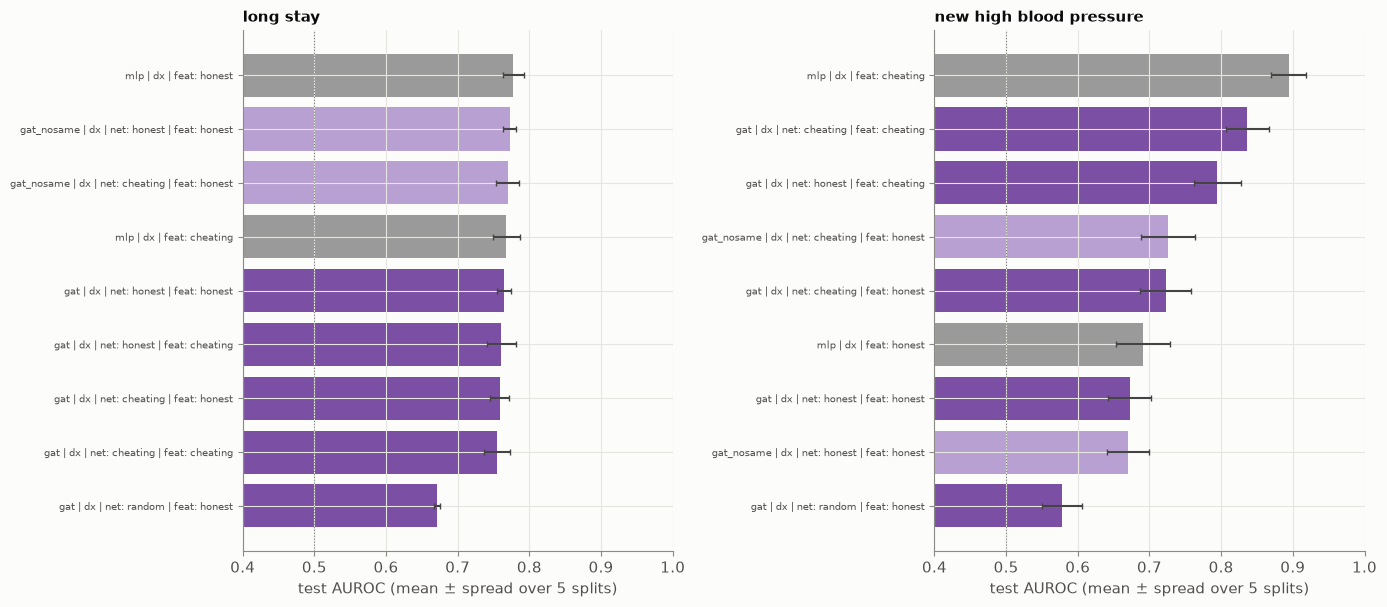

In [12]:
COLOR = {"gat": "#7b4fa3", "mlp": "#9a9a9a", "gat_nosame": "#b9a0d3"}
fig, axes = plt.subplots(1, len(TASKS), figsize=(14, 6.2), sharex=False)
for ax, t in zip(np.atleast_1d(axes), TASKS):
    s = tables[t].sort_values("mean")
    ax.barh(s.index, s["mean"], xerr=s["sd"], color=[COLOR[i.split(" | ")[0]] for i in s.index], ecolor="#444", capsize=2)
    ax.axvline(0.5, color="grey", lw=0.8, ls=":"); ax.set_xlim(0.4, 1.0)
    ax.set_title(TASKS[t]); ax.set_xlabel(f"test AUROC (mean ± spread over {len(SEEDS)} splits)")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
nf.save(fig, p.figures / "15_gat.png")
plt.show()

In [13]:
# aggregate numbers only (no patient data)
pd.concat({TASKS[t]: res[t] for t in TASKS}, names=["question"]).reset_index(level=0) \
  .to_csv(p.results / "gat_results.csv", index=False)
att.drop(columns=["config"]).to_csv(p.results / "gat_attention.csv", index=False)

## What we learned

*(fill in after running)*

- **Does the network help at all?** `gat − mlp` on the honest network, per question. If it is within its spread of zero, GAT is just reading each stay's own features, as GraphSAGE was.
- **Does learned attention change that?** `gat − sage` (the GAT-minus-GraphSAGE table). If learning the weights does not help, the network has no useful neighbours to listen to.
- **What does attention do?** Near the uniform values and entropy near 1: no selection among neighbours. `self_share` well above uniform: the model mostly ignores the network. A gap between `same_patient_att` and `same_patient_links`: it prefers (or avoids) the same person's other admissions.
- **Is it the network, or just having a graph?** `gat` on the real network vs the random one.
- **Does cheating show up?** Cheating *diagnoses* should lift blood pressure (notebook 03) and not long stay (notebook 02). Does a cheating *network* change anything once the features are honest?
- **Against linear and GraphSAGE.** Is GAT better, and if so is it the network or the nonlinearity (compare `mlp`)?
- **Year.** Does any model's score survive within year bands?
- **CLMBR** (only if `CLMBR_PATH` was set in notebook 12).

## Read these results carefully

- **Transductive.** Test stays' features, and their links to training stays, take part in message passing. No test outcome is used, so this is not label leakage.
- **Attention is not an explanation of the model.** It shows how each layer weights neighbours, not why the prediction came out as it did, and it is computed from the two stays' features only.
- **Possible time leak in same-patient links.** A link to a patient's *later* stay brings in that stay's record. `gat_nosame` shows how much the result depends on those links at all.
- **Calendar year.** Year alone scores about 0.64 on blood pressure; a model near that has learned little else.
- **Selection on validation.** Settings and stopping epoch come from the validation stays, so the validation score is slightly optimistic; the test score is untouched by that.
- **Small positive counts.** Blood pressure has about 90 positive test stays, so differences of a point or two are noise. Prefer the paired tables to eyeballing the bars.
- **Small search.** Two settings, 4 heads, 64 hidden. A larger search would be needed before saying GAT "cannot" do better.